# Road Accident Risk Prediction — ML Notebook

**Dataset:** `road_accident_risk_dataset_synthetic.csv` — 5,000 rows  
**Target:** `risk_level` (Low / Medium / High)

> **Honest limitation:** This is a synthetic demonstration dataset. Risk labels were generated from a simulated rule-based score, not verified real-world crash outcomes. The evaluation metrics describe how well models reproduce these synthetic labels; they are not evidence of real-world accident prediction. Do not tune or alter labels just to claim 85–88% accuracy. Use a real, documented dataset for a defensible project result.

This notebook includes preprocessing, stratified train/test split, Logistic Regression, Decision Tree, Random Forest, Extra Trees, and XGBoost, cross-validation, accuracy, precision, recall, F1-score, confusion matrices, ROC curves, multiclass ROC-AUC, and feature importance.

If XGBoost is not installed in your environment, run `%pip install xgboost` in a notebook cell, then restart the kernel.

In [1]:
%pip install xgboost


  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.


## 1. Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_auc_score, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

RANDOM_STATE = 42

## 2. Load the CSV

In [4]:
df = pd.read_csv("road_accident_risk_dataset_synthetic.csv")
print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (5000, 15)


,weather_condition,road_surface,road_type,lighting_condition,hour,traffic_density,visibility_km,speed_limit_kmh,estimated_speed_kmh,junction_type,road_quality,pedestrian_activity,month,weekend,risk_level
0,Rain,Wet,Urban Road,Daylight,21,Medium,10.700000,50,65.2,Roundabout,Good,Medium,2,No,Low
1,Cloudy,Dry,Urban Road,Daylight,17,Low,9.400000,40,54.5,Sharp Curve,Poor,High,4,Yes,Low
2,Fog,Dry,National Highway,Daylight,4,Low,9.862568,100,102.1,Sharp Curve,Fair,Medium,6,No,Medium
3,Rain,Wet,National Highway,Dark - Lit,23,High,9.500000,60,57.6,Straight,Poor,Low,8,No,Medium
4,Clear,Wet,State Highway,Daylight,23,Medium,12.700000,40,32.6,Intersection,Fair,Low,11,No,Medium


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   weather_condition    5000 non-null   str    
 1   road_surface         5000 non-null   str    
 2   road_type            5000 non-null   str    
 3   lighting_condition   5000 non-null   str    
 4   hour                 5000 non-null   int64  
 5   traffic_density      5000 non-null   str    
 6   visibility_km        5000 non-null   float64
 7   speed_limit_kmh      5000 non-null   int64  
 8   estimated_speed_kmh  5000 non-null   float64
 9   junction_type        5000 non-null   str    
 10  road_quality         5000 non-null   str    
 11  pedestrian_activity  5000 non-null   str    
 12  month                5000 non-null   int64  
 13  weekend              5000 non-null   str    
 14  risk_level           5000 non-null   str    
dtypes: float64(2), int64(3), str(10)
memory usage: 58

## 3. Inspect data quality and target balance

Missing values per column:


weather_condition      0
road_surface           0
road_type              0
lighting_condition     0
hour                   0
traffic_density        0
visibility_km          0
speed_limit_kmh        0
estimated_speed_kmh    0
junction_type          0
road_quality           0
pedestrian_activity    0
month                  0
weekend                0
risk_level             0
dtype: int64

Duplicate rows: 0
\nTarget distribution:


risk_level
Low       3000
Medium    1250
High       750
Name: count, dtype: int64

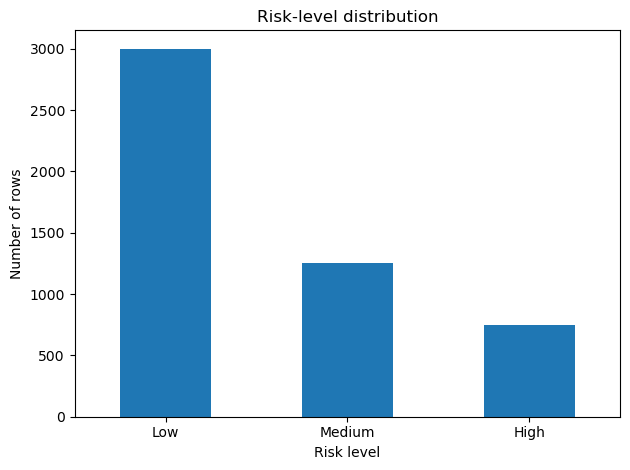

In [5]:
print("Missing values per column:")
display(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\\nTarget distribution:")
display(df["risk_level"].value_counts())
df["risk_level"].value_counts().plot(kind="bar", rot=0, title="Risk-level distribution")
plt.xlabel("Risk level")
plt.ylabel("Number of rows")
plt.tight_layout()
plt.show()

## 4. Separate features and target
We use only pre-trip conditions. `risk_level` is the label to predict; it must not be included in the input features.

In [6]:
target = "risk_level"
X = df.drop(columns=[target])

# XGBoost expects class labels encoded as consecutive integers for multiclass classification.
label_encoder = LabelEncoder()
y = pd.Series(label_encoder.fit_transform(df[target]), index=df.index, name=target)
class_names = label_encoder.classes_

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Class mapping:")
for encoded_value, class_name in enumerate(class_names):
    print(f"{encoded_value} = {class_name}")
print("\\nCategorical features:", categorical_features)
print("Numeric features:", numeric_features)

Class mapping:
0 = High
1 = Low
2 = Medium
\nCategorical features: ['weather_condition', 'road_surface', 'road_type', 'lighting_condition', 'traffic_density', 'junction_type', 'road_quality', 'pedestrian_activity', 'weekend']
Numeric features: ['hour', 'visibility_km', 'speed_limit_kmh', 'estimated_speed_kmh', 'month']


C:\Users\abhir\AppData\Local\Temp\ipykernel_14552\1593393289.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns.tolist()


## 5. Train/test split and preprocessing
The test set is held out for final evaluation. Imputation and scaling/encoding are fitted within the pipeline to avoid fitting preprocessing on the test set.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 4000 | Test rows: 1000


## 6. Train and compare models

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=250, min_samples_leaf=3, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=250, min_samples_leaf=3, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

pipelines = {
    name: Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    for name, model in models.items()
}

results = []
fitted_models = {}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)
    classes = pipe.named_steps["model"].classes_
    y_test_bin = label_binarize(y_test, classes=classes)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "F1_weighted": f1_score(y_test, pred, average="weighted", zero_division=0),
        "ROC_AUC_ovr_macro": roc_auc_score(y_test, proba, labels=classes, multi_class="ovr", average="macro")
    })

results_df = pd.DataFrame(results).sort_values("F1_macro", ascending=False)
display(results_df.style.format({c: "{:.3f}" for c in results_df.columns if c != "Model"}))
print("Metrics are measured on the held-out test set; results are not guaranteed to fall within any target range.")

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,ROC_AUC_ovr_macro
0,Logistic Regression,0.765,0.724,0.678,0.697,0.757,0.902
4,XGBoost,0.741,0.692,0.635,0.656,0.730,0.877
2,Random Forest,0.709,0.650,0.637,0.643,0.708,0.847
3,Extra Trees,0.696,0.633,0.642,0.637,0.700,0.835
1,Decision Tree,0.652,0.553,0.551,0.551,0.646,0.775


Metrics are measured on the held-out test set; results are not guaranteed to fall within any target range.


## 7. Cross-validation
Cross-validation estimates performance across several training/validation folds. Here we report mean and standard deviation of accuracy on the training portion; it is **not** the same as the held-out test accuracy.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    cv_rows.append({"Model": name, "CV accuracy mean": scores.mean(), "CV accuracy std": scores.std()})
cv_df = pd.DataFrame(cv_rows).sort_values("CV accuracy mean", ascending=False)
display(cv_df.style.format({"CV accuracy mean": "{:.3f}", "CV accuracy std": "{:.3f}"}))

,Model,CV accuracy mean,CV accuracy std
0,Logistic Regression,0.753,0.015
4,XGBoost,0.734,0.014
2,Random Forest,0.713,0.009
3,Extra Trees,0.689,0.013
1,Decision Tree,0.661,0.008


## 8. Detailed metrics and confusion matrix for the best macro-F1 model

Selected model: Logistic Regression
Accuracy: 0.765
Precision (macro): 0.7242
Recall (macro): 0.6782
F1-score (macro): 0.6971
F1-score (weighted): 0.7571
\nClassification report:
              precision    recall  f1-score   support

        High       0.79      0.63      0.70       150
         Low       0.83      0.91      0.87       600
      Medium       0.56      0.49      0.52       250

    accuracy                           0.77      1000
   macro avg       0.72      0.68      0.70      1000
weighted avg       0.76      0.77      0.76      1000



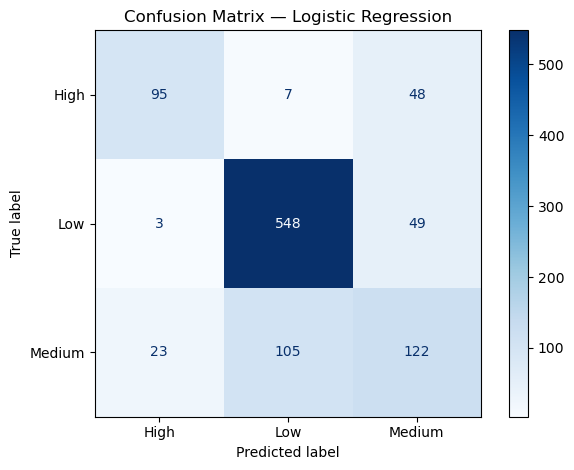

In [11]:
best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)
class_ids = best_model.named_steps["model"].classes_
class_names = label_encoder.classes_

print("Selected model:", best_name)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision (macro):", round(precision_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("Recall (macro):", round(recall_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("F1-score (macro):", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("F1-score (weighted):", round(f1_score(y_test, y_pred, average="weighted", zero_division=0), 4))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, labels=np.arange(len(class_names)), target_names=class_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=class_ids)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

## 9. ROC curves and multiclass AUC
For a three-class target, we binarize each class and plot one-vs-rest ROC curves. AUC values depend on the dataset and model; do not assume a particular value in advance.

In [ ]:
y_test_bin = label_binarize(y_test, classes=np.arange(len(class_names)))
auc_macro = roc_auc_score(y_test, y_proba, labels=np.arange(len(class_names)), multi_class="ovr", average="macro")
print("Macro one-vs-rest ROC-AUC:", round(auc_macro, 4))

plt.figure(figsize=(8, 6))
for i, class_name in enumerate(class_names):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i], y_proba[:, i], name=f"{class_name} (AUC)"
    )
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.title(f"One-vs-Rest ROC Curves — {best_name}")
plt.tight_layout()
plt.show()

## 10. Feature importance (tree-based model)

In [ ]:
tree_name = "Random Forest"
tree_pipe = fitted_models[tree_name]
feature_names = tree_pipe.named_steps["preprocessor"].get_feature_names_out()
importances = tree_pipe.named_steps["model"].feature_importances_
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importances})
importance_df = importance_df.sort_values("Importance", ascending=False).head(15)

display(importance_df)
importance_df.sort_values("Importance").plot(
    x="Feature", y="Importance", kind="barh", legend=False, figsize=(9, 6),
    title="Top 15 Feature Importances — Random Forest"
)
plt.tight_layout()
plt.show()

## 11. Try a sample prediction
The sample uses the same columns as the training data. Treat the predicted category as a demonstration only—not a safety guarantee or route recommendation.

In [ ]:
sample = pd.DataFrame([{
    "weather_condition": "Rain",
    "road_surface": "Wet",
    "road_type": "Urban Road",
    "lighting_condition": "Dark - Unlit",
    "hour": 21,
    "traffic_density": "High",
    "visibility_km": 3.0,
    "speed_limit_kmh": 50,
    "estimated_speed_kmh": 65.0,
    "junction_type": "Intersection",
    "road_quality": "Fair",
    "pedestrian_activity": "High",
    "month": 7,
    "weekend": "Yes"
}])
predicted_class_id = int(best_model.predict(sample)[0])
print("Predicted risk level:", label_encoder.inverse_transform([predicted_class_id])[0])
print("Class probabilities:")
display(pd.DataFrame(best_model.predict_proba(sample), columns=class_names).round(3))

## 12. Interpretation and limitations
- Accuracy = correct predictions / all predictions.
- Precision (macro) = average per-class precision; it penalizes false positive assignments across classes.
- Recall (macro) = average per-class recall; it shows how well each class is detected.
- F1 (macro) = average per-class harmonic mean of precision and recall.
- ROC-AUC (macro OVR) evaluates one-vs-rest class ranking performance.
- CV accuracy mean/std summarizes validation-fold performance and variability.

**Do not claim 85–88% accuracy unless the actual held-out test evaluation produces that value.** To make credible real-world claims, use a documented real dataset, define the target from observed outcomes, prevent leakage, and evaluate on an appropriate time- or location-based holdout.